# 03. Scenarios: revenue at risk

This notebook applies what-if scenarios to the 12-month baseline forecast from `02_forecast`. The baseline is read from `outputs/tables/forecast_12m.csv` each run, so the numbers update if the forecast changes. Values are importer-reported (US and EU27) in current USD.

| Scenario | What changes |
|---|---|
| S1 | US apparel demand falls 10%. Each US product group responds with its own sensitivity. |
| S2 | EU duty-free access ends and the 12% MFN duty applies (no GSP). Post-2029 only. |
| S2b | Same, but Bangladesh gets standard GSP, so the duty is 9.6%. |
| S3 | Stress test, not a dated forecast: S1 and S2 (mid) added together. |
| S4 | A repeat of the July-August 2024 unrest for two months. |

S3 has no date. The EU duty in S2 cannot apply before Everything But Arms access ends, about November 2029 at the earliest, while S1 is a shock inside the current window. S3 just shows how much the two together would take out of one year at today's volume.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
import scenarios as sc
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
res, betas, shock24 = sc.run()
print("Forecast window:", res["window"].iloc[0])
lagged = sc.disruption_2024_lagged(sc.load_history())
bench = sc.s2_benchmark(res)


Forecast window: 2026-08 to 2027-07


## S1. US demand sensitivity

FRED was down when this was built, and US imports from all countries are not in the repo. So the link from US demand to Bangladesh's US sales is split in two:

1. Each group's beta: the slope of its annual log growth on the log growth of total US imports from Bangladesh (2011-2025). A beta above 1 means the group swings more than the total.
2. The total's elasticity to US apparel demand: assumed 1.0, with 0.8 and 1.5 as low and high cases.

A group's response to the -10% shock is -10% x beta x elasticity.

In [2]:
betas.round(2)

,chapter,product_group,beta,r2,n_years,years
0,Knit,Coats & jackets,0.96,0.52,15,2011-2025
1,Knit,Knit shirts & blouses,1.31,0.64,15,2011-2025
2,Knit,Knit suits & trousers,1.06,0.54,15,2011-2025
3,Knit,Other apparel,0.83,0.58,15,2011-2025
4,Knit,Sweaters & pullovers (knit),0.93,0.73,15,2011-2025
5,Knit,T-shirts & vests (knit),1.28,0.70,15,2011-2025
6,Knit,Underwear & nightwear,0.87,0.59,15,2011-2025
7,Woven,Coats & jackets,0.69,0.41,15,2011-2025
8,Woven,Other apparel,0.95,0.73,15,2011-2025
9,Woven,Underwear & nightwear,0.59,0.22,15,2011-2025


## S4. Measuring the July-August 2024 shortfall

Expected value for each month = the same month in 2023, scaled by H1 2024 / H1 2023 growth. The table compares that with actual imports.

In [3]:
shock24.assign(actual=lambda d: d.actual/1e6, expected=lambda d: d.expected/1e6).round(3)

,market,chapter,month,actual,expected,shortfall_pct
0,EU,Knit,2024-07,1056.685,1039.322,0.017
1,EU,Knit,2024-08,1121.940,988.179,0.135
2,EU,Woven,2024-07,640.955,653.235,-0.019
3,EU,Woven,2024-08,666.991,623.733,0.069
4,US,Knit,2024-07,260.052,255.011,0.020
5,US,Knit,2024-08,234.706,215.936,0.087
6,US,Woven,2024-07,442.629,428.666,0.033
7,US,Woven,2024-08,392.278,354.402,0.107


US and EU import records show no shortfall in July or August 2024. Both months came in above the expected level. A shipping lag of four to eight weeks could push the loss into September or October, so the table below checks those months and the July to October total.


In [4]:
lagged.assign(actual=lambda d: d.actual/1e6, expected=lambda d: d.expected/1e6).round(3)

,market,chapter,period,actual,expected,shortfall_pct
0,EU,Knit,Sep 2024,1076.304,884.199,0.217
1,EU,Knit,Oct 2024,1230.196,814.834,0.510
2,EU,Knit,Sep-Oct 2024,2306.500,1699.033,0.358
3,EU,Knit,Jul-Oct 2024,4485.124,3726.534,0.204
4,EU,Woven,Sep 2024,630.423,568.775,0.108
5,EU,Woven,Oct 2024,682.587,499.573,0.366
6,EU,Woven,Sep-Oct 2024,1313.010,1068.348,0.229
7,EU,Woven,Jul-Oct 2024,2620.957,2345.316,0.118
8,US,Knit,Sep 2024,272.975,222.158,0.229
9,US,Knit,Oct 2024,296.418,223.903,0.324


Importer data show no measurable loss. September and October 2024 were 11% to 51% above the expected level in every series, and July to October as a whole was 12% to 22% above it. Shipments were delayed, not lost. Part of the late-2024 rise is a weak base, since imports fell in late 2023, so these numbers do not show that the unrest helped.

Bangladesh-side monthly export data (EPB) in this repo start only in December 2024, so the shock cannot be measured at the source. S4 applies the measured shortfall capped at zero, which gives no revenue at risk. A reader should take S4 = 0 to mean "no loss visible in importer data", not "the unrest cost nothing". Factory days lost, air-freight costs and late-delivery discounts would hit margins, and none of them show up in import values.


## Results

In [5]:
res.to_csv(ROOT / "outputs/tables/scenarios_revenue_at_risk.csv", index=False,
           columns=["scenario","market","chapter","product_group","window","baseline_usd","scenario_usd","change_usd","change_pct"])
sc.to_powerbi(res).to_csv(ROOT / "data/processed/powerbi/fact_scenarios.csv", index=False)
ass = sc.assumptions(betas, shock24)
ass.to_csv(ROOT / "outputs/tables/scenario_assumptions.csv", index=False)
head = res.groupby(["scenario","market"])[["baseline_usd","change_usd"]].sum()
head["change_pct"] = head["change_usd"] / head["baseline_usd"]
(head.assign(baseline_usd=lambda d: d.baseline_usd/1e6, change_usd=lambda d: d.change_usd/1e6)
     .rename(columns={"baseline_usd":"baseline_musd","change_usd":"change_musd"}).round(3))

baseline_musd  change_musd  change_pct
scenario                                          market                                        
S1 US demand -10% [high]                          US           7899.261    -1182.487      -0.150
S1 US demand -10% [low]                           US           7899.261     -630.660      -0.080
S1 US demand -10% [mid]                           US           7899.261     -788.325      -0.100
S2 EU 12% MFN duty (post-2029, no GSP) [high]     EU          22397.360   -12604.596      -0.563
S2 EU 12% MFN duty (post-2029, no GSP) [low]      EU          22397.360    -5904.037      -0.264
S2 EU 12% MFN duty (post-2029, no GSP) [mid]      EU          22397.360    -7761.379      -0.347
S2b EU 9.6% standard-GSP duty (post-2029) [mid]   EU          22397.360    -6536.358      -0.292
S3 Stress test S1 + S2 mid (not a dated forecast) EU          22397.360    -7761.379      -0.347
                                                  US           7899.261     -788.325      -0.100
S4 Repeat Jul-Aug 2024 disruption                 EU          22397.360        0.000       0.000
                                                  US           7899.261        0.000       0.000

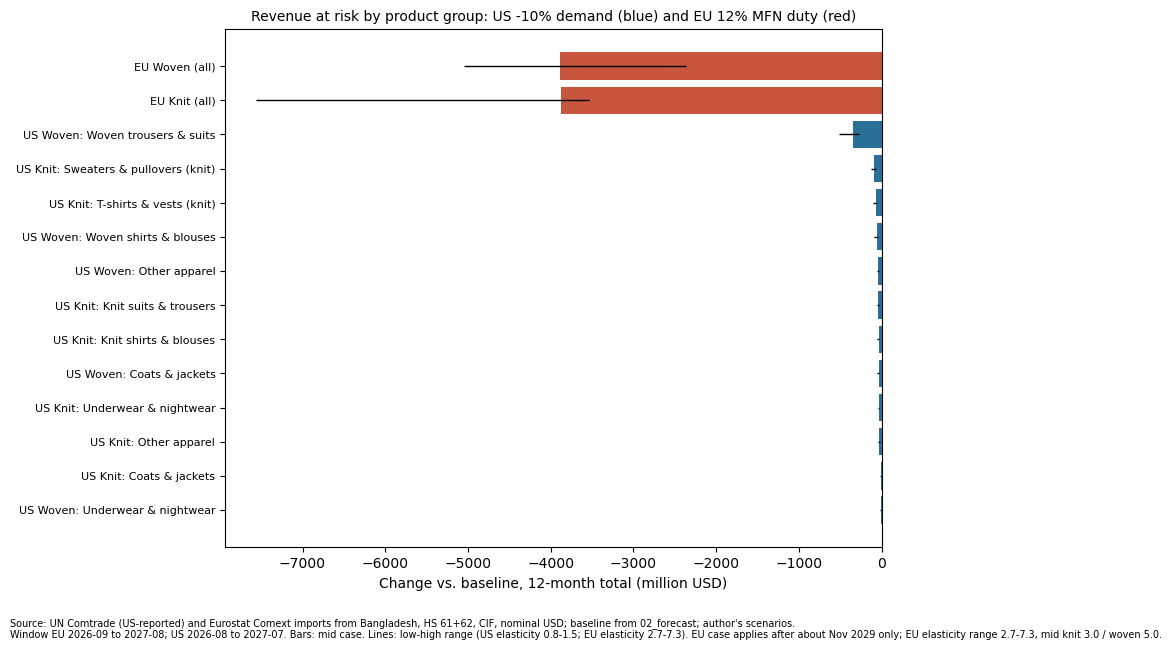

In [6]:
SRC = "Source: UN Comtrade (US-reported) and Eurostat Comext imports from Bangladesh, HS 61+62, CIF, nominal USD; baseline from 02_forecast; author's scenarios."
w = "; ".join(f"{m} {v}" for m, v in res.groupby("market")["window"].first().items())
s1 = res[res.scenario == f"{sc.S1} [mid]"].set_index(["market","chapter","product_group"])
lo = res[res.scenario == f"{sc.S1} [low]"].set_index(["market","chapter","product_group"])
hi = res[res.scenario == f"{sc.S1} [high]"].set_index(["market","chapter","product_group"])
s2 = {k: res[res.scenario == f"{sc.S2} [{k}]"].set_index(["market","chapter","product_group"]) for k in ("low","mid","high")}
mid = pd.concat([s1.change_usd, s2["mid"].change_usd])
low = pd.concat([lo.change_usd, s2["low"].change_usd])
high = pd.concat([hi.change_usd, s2["high"].change_usd])
order = mid.sort_values(ascending=False).index
lab = [f"{m} {c}: {p}" if m == "US" else f"EU {c} (all)" for m, c, p in order]
fig, ax = plt.subplots(figsize=(9, 6.5))
y = range(len(order))
ax.barh(y, mid[order]/1e6, color=["#2a6f97" if m == "US" else "#c8553d" for m,_,_ in order])
ax.hlines(y, high[order]/1e6, low[order]/1e6, color="black", lw=1)
ax.set_yticks(list(y)); ax.set_yticklabels(lab, fontsize=8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Change vs. baseline, 12-month total (million USD)")
ax.set_title("Revenue at risk by product group: US -10% demand (blue) and EU 12% MFN duty (red)", fontsize=10)
fig.text(0.01, 0.01, SRC + f"\nWindow {w}. Bars: mid case. Lines: low-high range (US elasticity 0.8-1.5; EU elasticity 2.7-7.3). EU case applies after about Nov 2029 only; EU elasticity range 2.7-7.3, mid knit 3.0 / woven 5.0.", fontsize=7)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(ROOT / "outputs/figures/fig_scen01_risk_by_group.png", dpi=150)

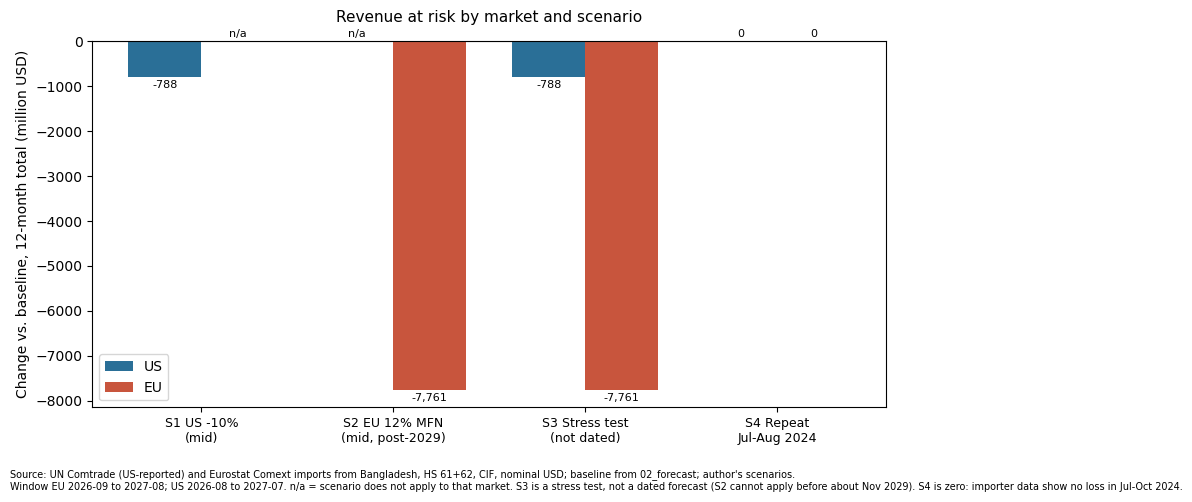

In [7]:
import numpy as np
keep = [f"{sc.S1} [mid]", f"{sc.S2} [mid]", sc.S3, sc.S4]
g = res[res.scenario.isin(keep)].groupby(["scenario","market"]).change_usd.sum().unstack(fill_value=0).reindex(keep)/1e6
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(g)); wd = 0.38
for i, (m, col) in enumerate([("US","#2a6f97"),("EU","#c8553d")]):
    b = ax.bar(x + (i-0.5)*wd, g[m], wd, label=m, color=col)
    applies = [not ((m == "EU" and k.startswith("S1")) or (m == "US" and k.startswith("S2"))) for k in g.index]
    ax.bar_label(b, labels=[(f"{v:,.0f}" if a else "n/a") for v, a in zip(g[m], applies)], fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(["S1 US -10%\n(mid)","S2 EU 12% MFN\n(mid, post-2029)","S3 Stress test\n(not dated)","S4 Repeat\nJul-Aug 2024"], fontsize=9)
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Change vs. baseline, 12-month total (million USD)")
ax.set_title("Revenue at risk by market and scenario", fontsize=11, pad=14)
ax.legend(loc="lower left")
fig.text(0.01, 0.01, SRC + f"\nWindow {w}. n/a = scenario does not apply to that market. S3 is a stress test, not a dated forecast (S2 cannot apply before about Nov 2029). S4 is zero: importer data show no loss in Jul-Oct 2024.", fontsize=7)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(ROOT / "outputs/figures/fig_scen02_risk_by_market.png", dpi=150)

## Assumptions and sources

Every input that is not measured from the data is listed below and saved to `outputs/tables/scenario_assumptions.csv`.

In [8]:
ass

,scenario,assumption,value,source
0,S1,US apparel demand shock,-10%,Scenario design (PLAN.md 1.3D)
1,S1,Elasticity of BD-to-US apparel imports to US apparel demand,1.0 (range 0.8-1.5),"Analyst assumption. FRED (DCAFRC1Q027SBEA) was unreachable (site maintenance, Oct 2026) and US imports from all coun..."
2,S1,Group sensitivity (beta) relative to BD-to-US total,Knit: Coats & jackets 0.96; Knit: Knit shirts & blouses 1.31; Knit: Knit suits & trousers 1.06; Knit: Other apparel ...,"OLS of annual log growth, US-reported imports from BD, 2011-2025 (rmg_long.csv)"
3,S2,Bangladesh LDC graduation date,24 Nov 2026 (deferral to 24 Nov 2029 requested; CDP supportive; UNGA decision not confirmed in sources found),UNGA res. 76/8 (Nov 2021) set 24 Nov 2026; ECOSOC (2026) referred the 3-year deferral request to the UNGA for a deci...
4,S2,EU EBA transition after graduation,3 years (EBA access to about Nov 2029; to about 2032 if graduation is deferred),"Regulation (EU) No 978/2012 (GSP Regulation), Art. 17(2): EBA arrangements end 3 years after the country leaves the ..."
5,S2,EU MFN duty on apparel (HS61/62) if no GSP+,12% (most lines; upper end for the two chapters),"EU Combined Nomenclature (Reg. (EEC) 2658/87, Annex I) conventional duty: 12% on most HS 61/62 lines, e.g. CN 6109 1..."
6,S2b,EU duty under standard GSP,9.6% (12% MFN cut by 20%),"Regulation (EU) No 978/2012, Art. 7: standard GSP cuts the MFN duty on textiles and clothing (Section XI) by 20%, so..."
7,S2,|Elasticity of EU import value to the duty factor (1 + t)|,"low 2.7 (both chapters); mid knit 3.00, woven 5.02; high 7.3 (both)","Low: Broda & Weinstein (2006, QJE 121(2)) median elasticity of substitution, US imports, SITC 5-digit, 1990-2001, as..."
8,S2,Pass-through and functional form,Full duty pass-through; value change = (1 + t)^(-e) - 1,"Constant-elasticity import demand. The cited tariff elasticities are estimated on import values before duty, which i..."
9,S2,Published benchmark,Bekkers & Cariola (2022): Bangladesh exports -14% (-$5.37bn of $37.6bn); exports to preference-granting markets -23%...,"WTO Staff Working Paper ERSD-2022-05, Tables 1-2 (actual preference use). Partial-equilibrium model with Fontagne et..."


## Notes on S2

- Bangladesh's LDC graduation date of 24 November 2026 was set by UN General Assembly resolution 76/8 (2021). The government asked to defer it to November 2029. ECOSOC sent the request to the General Assembly for a decision before 24 November 2026. As of 22 October 2026 no decision was found in the sources checked.
- Under the EU GSP Regulation (EU) No 978/2012, Article 17, Everything But Arms access ends three years after a country leaves the LDC list. That puts the end of EBA at about November 2029, or about 2032 if graduation is deferred. No tariff change falls inside this forecast window.
- The 12% rate is the EU's conventional (MFN) duty on most HS 61 and 62 lines, for example cotton T-shirts (CN 6109 10 00). A few lines carry lower rates, so 12% is the upper end. Standard GSP cuts the textile and clothing duty by 20%, to 9.6%. S2 is the case with no GSP at all, and S2b is the standard-GSP case. GSP+ would bring the duty back to 0%.
- **Elasticities.** What matters is how far EU buyers switch to other suppliers when Bangladeshi clothes get dearer. The cases use published estimates of how import value responds to a tariff:
  - Low, 2.7: the median elasticity of substitution in Broda and Weinstein (2006) for US imports at the SITC 5-digit level, 1990-2001.
  - Mid, 3.0 for knit and 5.0 for woven: the mean HS6 tariff elasticities for HS 61 and HS 62 in Fontagné, Guimbard and Orefice (2022, Table A2).
  - High, 7.3: the median over all products in the same paper.
- Value change = (1 + duty)^(-elasticity) - 1, with the duty fully passed on to buyers.
- S2 asks what one year at today's volume would lose. It is not a forecast.

### How S2 compares with a published estimate

Bekkers and Cariola (2022) at the WTO model LDC graduation with the same family of elasticities. They project that Bangladesh's exports to markets that give LDC preferences fall 23% ($6.2bn) for a 7.9-point rise in the effective tariff. Total exports fall 14% ($5.4bn) once some of the lost sales move to other markets.

Our S2 mid case is larger, at about 35%. Three reasons:
- We apply the full 12% duty. Their average tariff rise is smaller because some trade already paid duty and some markets cut duties less.
- We assume full pass-through. They let Bangladeshi export prices fall, which absorbs part of the duty.
- We do not let lost EU sales move to other markets.

The standard-GSP case (S2b, 29%) is closer to their figure. Read S2 as an upper bound for the EU market alone.


In [9]:
bench.to_csv(ROOT / "outputs/tables/s2_benchmark.csv", index=False)
bench.round(3)

,estimate,coverage,loss_usd_bn,loss_pct
0,"This repo: S2 EU 12% MFN duty (post-2029, no GSP) [low]","EU27 imports of HS 61+62, 12-month baseline",5.904,0.264
1,"This repo: S2 EU 12% MFN duty (post-2029, no GSP) [mid]","EU27 imports of HS 61+62, 12-month baseline",7.761,0.347
2,"This repo: S2 EU 12% MFN duty (post-2029, no GSP) [high]","EU27 imports of HS 61+62, 12-month baseline",12.605,0.563
3,This repo: S2b EU 9.6% standard-GSP duty (post-2029) [mid],"EU27 imports of HS 61+62, 12-month baseline",6.536,0.292
4,"Bekkers & Cariola (2022), WTO ERSD-2022-05: preference-granting markets","All goods, all preference-granting markets, +7.9 pp effective tariff",6.199,0.230
5,"Bekkers & Cariola (2022), WTO ERSD-2022-05: all markets","All goods, all markets, net of trade diversion",5.373,0.140


Sources: [EU GSP Regulation 978/2012](https://eur-lex.europa.eu/eli/reg/2012/978/oj), [EU TARIC](https://ec.europa.eu/taxation_customs/dds2/taric/), [Bekkers and Cariola (2022), WTO ERSD-2022-05](https://www.wto.org/english/res_e/reser_e/ersd202205_e.pdf), [Fontagné, Guimbard and Orefice, CESifo WP 8491 (published in J. Int. Econ. 137, 2022)](https://www.ifo.de/DocDL/cesifo1_wp8491.pdf), Broda and Weinstein (2006), "Globalization and the Gains from Variety", QJE 121(2), [WTO-EIF, Trade impacts of LDC graduation (2020)](https://www.wto.org/english/res_e/booksp_e/trade_impacts_of_ldc_graduation.pdf), [The Financial Express](https://www.thefinancialexpress.com.bd/national/ecosoc-refers-bangladeshs-ldc-extension-to-unga), [The Daily Star, EU GSP rules and Bangladesh's RMG](https://www.thedailystar.net/business/column/news/eu-gsp-rules-and-bangladeshs-rmg-4218431), [CPD](https://cpd.org.bd/is-deferment-of-ldc-graduation-a-viable-option-for-bangladesh/), [TBS News](https://www.tbsnews.net/analysis/what-if-we-graduate-ldc-next-year-or-three-years-later-1297226).
